# 第184章: Conditional GAN — 条件を付けると何が直り、何が隠れるか

## ラベル条件付け・projection discriminator・忠実度と多様性のつまみ

---

### このノートブックの位置づけ

182 と 183 で、GAN の失敗を**数値で**切り分けました。

| 章 | 測ったこと |
|---|---|
| **182** | 標準設定の GAN は**比率の誤り**を起こす（占有率が 4 倍偏る）。1つの指標では3つの失敗を区別できない |
| **183** | 距離を $W_1$ に替えると勾配消失は構造的に消える。ただし 182 の比率の誤りは**1次元でしか測っていない**（宿題として残した） |

本章は条件付けを入れます。条件付けは比率の誤りに**効きます**が、
効き方が素朴な予想と違いました。そして**182 の主要な診断指標が使えなくなります**。

### 本章で確かめること

1. 条件付けは 182 の比率の誤りを直すか（同時に 183 の宿題も閉じる）
2. 占有率という指標が条件付きモデルでは**恒等的に 0** になること
3. 条件を判別器に渡さないと何が起きるか（「無視する」ではない）
4. 条件付けの3方式（concat / projection / 補助分類器）の比較
5. 忠実度と多様性のつまみ — GAN の切断トリックと拡散の CFG（42章）を同じ指標で測る
6. 条件が連続値のとき、学習に無い条件へ外挿できるか

### 前提

- **182**（モード崩壊の4指標）、**183**（WGAN-GP）
- **42**（classifier-free guidance）— 第5節で数値的に裏づけ直します

## 目次

1. [環境セットアップ](#setup)
2. [条件付けは比率の誤りを直すか](#fix-proportions)
3. [条件を判別器に渡さないと何が起きるか](#no-cond-d)
4. [条件付けの3方式](#methods)
5. [忠実度と多様性のつまみ — 切断トリックと CFG](#knobs)
6. [条件が連続値のとき](#continuous)
7. [実装でつまずいた3点](#pitfalls)
8. [まとめとチートシート](#summary)
9. [自己評価クイズ](#quiz)

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("torch:", torch.__version__)

torch: 2.9.1


<a id="fix-proportions"></a>
## 2. 条件付けは比率の誤りを直すか

182 と同じ8峰リングを使います。違いは**各点がどのモードから来たかをラベルとして持つ**ことです。

$$y \in \{0,\dots,7\}, \quad x \mid y \sim \mathcal{N}(\mu_y, 0.25^2 I)$$

条件付き GAN は $G(z, y)$ と $D(x, y)$ を学習します。生成するときは
**自分で $y$ を選びます**。ここが本章の仕掛けの源です。

### 指標を4つから6つに増やす

182 の4指標（被覆・占有率・最近傍距離・ED）に、条件付きモデル用の2つを足します。

| 指標 | 何を測るか |
|---|---|
| 占有率の最大偏差 | どのモードがどれだけ出たか（182） |
| 最近傍距離 | サンプルが互いに潰れていないか（182） |
| エネルギー距離 ED | 分布全体のずれ（182） |
| **条件遵守率** | 指定した $y$ のサンプルが、実際に $y$ のモードに落ちた割合 |
| **中心ずれ** | 条件 $y$ の生成サンプルの平均が $\mu_y$ からどれだけ離れているか |
| **広がり** | 条件 $y$ の生成サンプルの標準偏差（真は 0.25） |

最後の2つは**条件ごとに**測ります。周辺分布だけ見ていると何が見えなくなるかが
第3節の主題です。

In [2]:
# ============================================================
# 8峰リング（ラベル付き）と6つの指標
# ============================================================

K = 8
_ang = torch.arange(K) * 2 * math.pi / K
RING = torch.stack([3 * _ang.cos(), 3 * _ang.sin()], -1)
RING_SD = 0.25

def sample_ring(n, seed=0):
    g = torch.Generator().manual_seed(seed)
    y = torch.randint(0, K, (n,), generator=g)
    return RING[y] + RING_SD * torch.randn(n, 2, generator=g), y

X_train, Y_train = sample_ring(8000, seed=0)
X_ref, Y_ref = sample_ring(10000, seed=2)


def nearest_mode(x):
    return ((x[:, None, :] - RING[None]) ** 2).sum(-1).argmin(-1)

def occupancy(S):
    occ = torch.bincount(nearest_mode(S), minlength=K).float() / len(S)
    return occ, float((occ - 1.0 / K).abs().max())

def energy_distance(X, Y, n=3000):
    X, Y = X[:n], Y[:n]
    return float(2 * torch.cdist(X, Y).mean()
                 - torch.cdist(X, X).mean() - torch.cdist(Y, Y).mean())

def nn_distance(X, n=3000):
    S = X[:n]
    D = torch.cdist(S, S)
    D.fill_diagonal_(float("inf"))
    return float(D.min(-1).values.median())

def adherence(S, y):
    # 指定した条件 y のサンプルが、実際に y のモードに落ちた割合
    return float((nearest_mode(S) == y).float().mean())

def per_condition(S, y):
    cen = torch.stack([(S[y == k].mean(0) - RING[k]).norm() for k in range(K)])
    sp = torch.stack([S[y == k].std(0).mean() for k in range(K)])
    per_ed = [energy_distance(S[y == k], X_ref[Y_ref == k]) for k in range(K)]
    return (float(cen.mean()), float(cen.max()), float(sp.mean()),
            float(np.mean(per_ed)), float(max(per_ed)))

# ★ 指標に渡す前に必ず並べ替える（第7節のつまずき 1）
PERM = torch.Generator().manual_seed(123)
def shuffled(S, y):
    p = torch.randperm(len(y), generator=PERM)
    return S[p], y[p]


TRUE, Y_TRUE = sample_ring(10000, seed=5)
Ts, Tys = shuffled(TRUE, Y_TRUE)
_, md_t = occupancy(Ts)
cen_t, cenmax_t, sp_t, ped_t, pedmax_t = per_condition(TRUE, Y_TRUE)
print("基準（真のサンプル・別のシード 10000点）")
print(f"  占有率の最大偏差 {md_t:.4f}   条件遵守率 {adherence(Ts, Tys):.4f}")
print(f"  ED {energy_distance(Ts, X_ref):.5f}   最近傍距離 {nn_distance(Ts):.5f}")
print(f"  中心ずれ 平均 {cen_t:.4f} / 最悪 {cenmax_t:.4f}   広がり {sp_t:.4f}（真の sd は {RING_SD}）")
print(f"  条件ごとの ED 平均 {ped_t:.5f} / 最悪 {pedmax_t:.5f}")
print()
print("-> モデルの指標はこの値に近いほど良い（0 にはならない。有限標本の誤差）")

基準（真のサンプル・別のシード 10000点）
  占有率の最大偏差 0.0032   条件遵守率 1.0000
  ED 0.00274   最近傍距離 0.02315
  中心ずれ 平均 0.0069 / 最悪 0.0132   広がり 0.2510（真の sd は 0.25）
  条件ごとの ED 平均 0.00079 / 最悪 0.00147

-> モデルの指標はこの値に近いほど良い（0 にはならない。有限標本の誤差）


In [3]:
# ============================================================
# 生成器と判別器 — 無条件版と条件付き版
# ============================================================

class GenUncond(nn.Module):
    def __init__(self, z_dim=2, hidden=128):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, n, y=None):
        return self.net(torch.randn(n, self.z_dim))


class GenCond(nn.Module):
    # z と「ラベルの埋め込み」を連結する（concat 方式）
    def __init__(self, z_dim=2, hidden=128, emb=8):
        super().__init__()
        self.z_dim = z_dim
        self.emb = nn.Embedding(K, emb)
        self.net = nn.Sequential(
            nn.Linear(z_dim + emb, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, n, y=None):
        if y is None:
            y = torch.randint(0, K, (n,))
        return self.net(torch.cat([torch.randn(n, self.z_dim), self.emb(y)], -1))


class DiscUncond(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))

    def forward(self, x, y=None):
        return self.net(x).squeeze(-1)


class DiscConcat(nn.Module):
    def __init__(self, hidden=128, emb=8):
        super().__init__()
        self.emb = nn.Embedding(K, emb)
        self.net = nn.Sequential(
            nn.Linear(2 + emb, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))

    def forward(self, x, y=None):
        return self.net(torch.cat([x, self.emb(y)], -1)).squeeze(-1)


bce = nn.BCEWithLogitsLoss()

def train_gan(GenCls, DiscCls, cond_g, cond_d,
              steps=4000, seed=0, batch=256, lr=2e-4):
    torch.manual_seed(seed)
    G, D = GenCls(), DiscCls()
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    for _ in range(steps):
        i = torch.randint(0, len(X_train), (batch,))
        x_real, y_real = X_train[i], Y_train[i]
        y_fake = torch.randint(0, K, (batch,))
        x_fake = G(batch, y_fake if cond_g else None).detach()
        ld = (bce(D(x_real, y_real if cond_d else None), torch.ones(batch))
              + bce(D(x_fake, y_fake if cond_d else None), torch.zeros(batch)))
        od.zero_grad()
        ld.backward()
        od.step()
        y_g = torch.randint(0, K, (batch,))
        x_g = G(batch, y_g if cond_g else None)
        og.zero_grad()
        bce(D(x_g, y_g if cond_d else None), torch.ones(batch)).backward()
        og.step()
    return G


# 183 の WGAN-GP を2次元に持ち上げる（183 で確かめた lambda=1, SiLU, n_critic=5）
class CriticUncond(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 1))

    def forward(self, x, y=None):
        return self.net(x).squeeze(-1)


def gradient_penalty(C, x_real, x_fake):
    a = torch.rand(len(x_real), 1)
    x_hat = (a * x_real + (1 - a) * x_fake).requires_grad_(True)
    g = torch.autograd.grad(C(x_hat).sum(), x_hat, create_graph=True)[0]
    return ((g.norm(dim=-1) - 1) ** 2).mean()


def train_wgan_gp(steps=1500, n_critic=5, seed=0, batch=256, lr=1e-4, lam=1.0):
    torch.manual_seed(seed)
    G, C = GenUncond(), CriticUncond()
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.9))
    oc = torch.optim.Adam(C.parameters(), lr=lr, betas=(0.5, 0.9))
    for _ in range(steps):
        for _ in range(n_critic):
            xr = X_train[torch.randint(0, len(X_train), (batch,))]
            xf = G(batch).detach()
            lc = -(C(xr).mean() - C(xf).mean()) + lam * gradient_penalty(C, xr, xf)
            oc.zero_grad()
            lc.backward()
            oc.step()
        og.zero_grad()
        (-C(G(batch)).mean()).backward()
        og.step()
    return G

print("定義完了")

定義完了


In [4]:
# ============================================================
# 4設定 × 5シード
# ============================================================

@torch.no_grad()
def eval_uncond(G):
    S = G(10000)
    _, mdev = occupancy(S)
    return dict(md=mdev, adh=float("nan"), ed=energy_distance(S, X_ref),
                nn=nn_distance(S), cen=float("nan"), sp=float("nan"),
                occ=occupancy(S)[0].numpy())


@torch.no_grad()
def eval_cond(G):
    y = torch.arange(K).repeat_interleave(1250)
    S = G(len(y), y)
    Sp, yp = shuffled(S, y)
    _, mdev = occupancy(Sp)
    cen, cenmax, sp, ped, pedmax = per_condition(S, y)
    return dict(md=mdev, adh=adherence(Sp, yp), ed=energy_distance(Sp, X_ref),
                nn=nn_distance(Sp), cen=cen, cenmax=cenmax, sp=sp,
                ped=ped, pedmax=pedmax, occ=occupancy(Sp)[0].numpy())


SEEDS = [0, 1, 2, 3, 4]
SETTINGS = [
    ("無条件 GAN（182 の標準設定）",
     lambda s: train_gan(GenUncond, DiscUncond, False, False, seed=s), eval_uncond),
    ("条件付き GAN（concat）",
     lambda s: train_gan(GenCond, DiscConcat, True, True, seed=s), eval_cond),
    ("条件付き G / 無条件 D",
     lambda s: train_gan(GenCond, DiscUncond, True, False, seed=s), eval_cond),
    ("無条件 WGAN-GP（183）",
     lambda s: train_wgan_gp(seed=s), eval_uncond),
]

t0 = time.time()
main_res = {}
print(f"{'設定':<30}{'最大偏差':>10}{'遵守率':>9}{'ED':>10}{'最近傍':>10}{'中心ずれ':>10}{'広がり':>9}")
print("-" * 88)
for tag, fit, ev in SETTINGS:
    ms = [ev(fit(s)) for s in SEEDS]
    main_res[tag] = ms
    f = lambda k: np.array([m[k] for m in ms])
    print(f"{tag:<30}{f('md').mean():10.4f}{f('adh').mean():9.4f}"
          f"{f('ed').mean():10.5f}{f('nn').mean():10.5f}"
          f"{f('cen').mean():10.4f}{f('sp').mean():9.4f}")
print("-" * 88)
print(f"5シードの平均。経過 {time.time() - t0:.0f}s")
print()
print("シードごとのばらつき")
for tag, ms in main_res.items():
    f = lambda k: np.array([m[k] for m in ms])
    print(f"  {tag:<30} ED {f('ed').min():.5f}〜{f('ed').max():.5f} "
          f"(比 {f('ed').max() / f('ed').min():.1f}倍)   "
          f"最大偏差 {f('md').min():.4f}〜{f('md').max():.4f}")
print()
print("占有率（seed 0。真は各 0.125）")
for tag, ms in main_res.items():
    print(f"  {tag:<30} {np.round(ms[0]['occ'], 3)}")

設定                                  最大偏差      遵守率        ED       最近傍      中心ずれ      広がり
----------------------------------------------------------------------------------------


無条件 GAN（182 の標準設定）                0.0913      nan   0.08997   0.02094       nan      nan


条件付き GAN（concat）                  0.0000   1.0000   0.02881   0.00705    0.2216   0.1117


条件付き G / 無条件 D                    0.0000   0.1500   0.02536   0.00856    3.5765   0.1255


無条件 WGAN-GP（183）                  0.0170      nan   0.03054   0.03915       nan      nan
----------------------------------------------------------------------------------------
5シードの平均。経過 135s

シードごとのばらつき
  無条件 GAN（182 の標準設定）             ED 0.03152〜0.14276 (比 4.5倍)   最大偏差 0.0649〜0.1171
  条件付き GAN（concat）               ED 0.02059〜0.03812 (比 1.9倍)   最大偏差 0.0000〜0.0000
  条件付き G / 無条件 D                 ED 0.02164〜0.03343 (比 1.5倍)   最大偏差 0.0000〜0.0000
  無条件 WGAN-GP（183）               ED 0.02639〜0.03362 (比 1.3倍)   最大偏差 0.0127〜0.0215

占有率（seed 0。真は各 0.125）
  無条件 GAN（182 の標準設定）             [0.223 0.065 0.209 0.061 0.224 0.073 0.076 0.069]
  条件付き GAN（concat）               [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
  条件付き G / 無条件 D                 [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
  無条件 WGAN-GP（183）               [0.127 0.138 0.122 0.115 0.136 0.118 0.131 0.112]


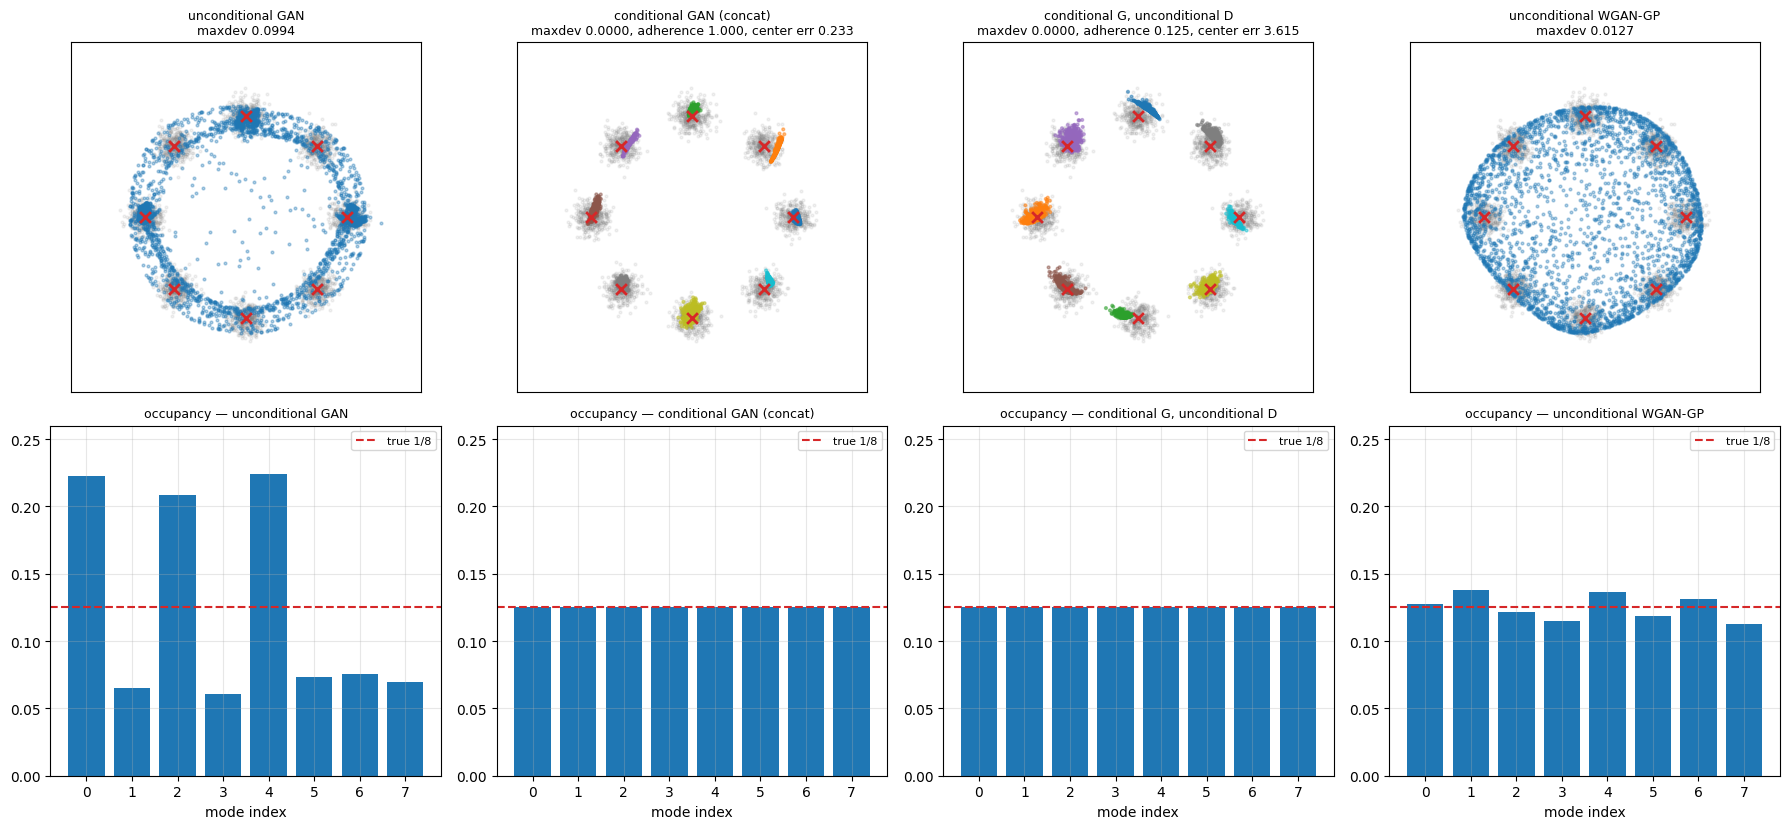

In [5]:
# ============================================================
# 図: 4設定の散布図と占有率
# ============================================================

fig, axes = plt.subplots(2, 4, figsize=(18, 8.4))
labels_en = {
    "無条件 GAN（182 の標準設定）": "unconditional GAN",
    "条件付き GAN（concat）": "conditional GAN (concat)",
    "条件付き G / 無条件 D": "conditional G, unconditional D",
    "無条件 WGAN-GP（183）": "unconditional WGAN-GP",
}
samples = {}
for ax, (tag, fit, ev) in zip(axes[0], SETTINGS):
    G = fit(0)
    with torch.no_grad():
        if ev is eval_uncond:
            S, yv = G(3000), None
        else:
            yv = torch.arange(K).repeat_interleave(375)
            S = G(len(yv), yv)
    samples[tag] = (S, yv)
    ax.scatter(X_ref[:3000, 0], X_ref[:3000, 1], s=4, alpha=0.10, color="tab:gray")
    if yv is None:
        ax.scatter(S[:, 0], S[:, 1], s=4, alpha=0.35, color="tab:blue")
    else:
        ax.scatter(S[:, 0], S[:, 1], s=4, alpha=0.5, c=yv.numpy(), cmap="tab10")
    ax.scatter(RING[:, 0], RING[:, 1], s=60, marker="x", color="tab:red", lw=2)
    m = main_res[tag][0]
    ttl = labels_en[tag] + f"\nmaxdev {m['md']:.4f}"
    if not math.isnan(m["adh"]):
        ttl += f", adherence {m['adh']:.3f}, center err {m['cen']:.3f}"
    ax.set_title(ttl, fontsize=9)
    ax.set_xlim(-5.2, 5.2)
    ax.set_ylim(-5.2, 5.2)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

for ax, (tag, _, _) in zip(axes[1], SETTINGS):
    occ = main_res[tag][0]["occ"]
    ax.bar(range(K), occ, color="tab:blue")
    ax.axhline(1 / K, color="tab:red", ls="--", lw=1.5, label="true 1/8")
    ax.set_ylim(0, 0.26)
    ax.set_xlabel("mode index")
    ax.set_title(f"occupancy — {labels_en[tag]}", fontsize=9)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 読み取れること

#### (1) 条件付けは比率の誤りを「直す」のではなく「消す」

| 設定 | 占有率の最大偏差 | シード間のばらつき |
|---|---|---|
| 無条件 GAN（182 の標準設定） | 0.0913 | 0.0649 〜 0.1171 |
| **条件付き GAN（concat）** | **0.0000** | 0.0000 〜 0.0000 |
| 無条件 WGAN-GP（183） | 0.0170 | 0.0127 〜 0.0215 |
| 基準（真のサンプル） | 0.0032 | — |

条件付きモデルの最大偏差は**厳密に 0** です。有限標本なのに誤差すら無いのは、
これが測定結果ではなく**定義**だからです。

生成するとき $y$ は**私が一様に 1250 個ずつ選んでいます**。
条件遵守率が 1.0000（指定した $y$ のモードに必ず落ちる）なら、
占有率は定義から各 $1/8$ になります。

> **182 の主要な診断指標が、条件付きモデルでは恒等式になります。**
> 「占有率が完璧だから比率の誤りは無い」とは言えません。
> 比率を決めているのはモデルではなく、サンプリング時の私です。

#### (2) 183 の宿題 — WGAN-GP は 8峰リングでも比率の誤りを直す

183 は $W_1$ の効果を1次元でしか測らず、「182 の比率の誤りに効くか」を宿題に残しました。
ここで閉じます。$y$ を選んでいないので、これは「消した」のではなく本当に直っています。

| | 最大偏差 | ED のシード間比 |
|---|---|---|
| 無条件 GAN | 0.0913 | 4.5 倍 |
| 無条件 WGAN-GP | **0.0170**（5.4 分の1） | **1.3 倍** |

183 は1次元で安定性を測りました。本章で測ったのは**シード間のばらつき**と占有率で、
学習中の振動は測っていません。言えるのは「8峰リングでも、比率の誤りとシード依存性に
$W_1$ が効く」までです。

#### (3) 条件付けの代償 — (b) を消して (c) を作る

| | 最近傍距離 | 広がり |
|---|---|---|
| 基準（真） | 0.02315 | 0.2510 |
| 条件付き GAN（concat） | 0.00705（**3.3 分の1**） | 0.1117（**2.2 分の1**） |
| 無条件 WGAN-GP | 0.03915 | — |

182 の3分類で言えば、**(b) 比率の誤りが消えて (c) 多様性の欠如が出ました**。
条件ごとに $z$ から狭い領域へ写すので、各条件の中で潰れやすくなります。

#### (4) いちばん重要な行 — 3行目

| | 条件遵守率 | 周辺の ED | 中心ずれ |
|---|---|---|---|
| 条件付き GAN（concat） | 1.0000 | 0.02881 | 0.2216 |
| **条件付き G / 無条件 D** | **0.1500**（偶然は 0.125） | **0.02536**（concat より**良い**） | **3.5765** |

条件付けが完全に失敗しているモデルが、**周辺分布の ED では concat より良い**のです。
占有率も 0.0000 で満点。捉えたのは中心ずれだけでした。

この設定で何が起きているのかを、次節で分割表にして見ます。

<a id="no-cond-d"></a>
## 3. 条件を判別器に渡さないと何が起きるか

前節の3行目「条件付き G / 無条件 D」は、生成器だけが $y$ を受け取り、
判別器は $x$ しか見ない設定です。

教科書的な説明はこうです。「判別器が $y$ を見ないので、生成器が $y$ を無視しても
罰されない。だから条件が効かなくなる」。

**この説明は半分しか当たっていません。** 条件遵守率が偶然と同じ水準まで落ちるのは
事実ですが、生成器は $y$ を**無視していません**。分割表を取って確かめます。

In [6]:
# ============================================================
# 条件 y × 着地したモード の分割表
# ============================================================

def cross_table(G, n_per=1250):
    y = torch.arange(K).repeat_interleave(n_per)
    with torch.no_grad():
        S = G(len(y), y)
    m = nearest_mode(S)
    tab = np.zeros((K, K), int)
    for k in range(K):
        tab[k] = torch.bincount(m[y == k], minlength=K).numpy()
    return tab, S, y


print("D に y を渡さない設定")
print(f"{'seed':>5}{'各条件の最頻モード':>32}{'置換か':>8}{'集中度':>9}{'遵守率':>9}")
print("-" * 63)
tables_nocond = []
for seed in [0, 1, 2]:
    G = train_gan(GenCond, DiscUncond, True, False, seed=seed)
    tab, S, y = cross_table(G)
    tables_nocond.append(tab)
    top = tab.argmax(1)
    # 集中度 = 各条件のサンプルが最頻モードに入った割合
    conc = (tab.max(1) / tab.sum(1)).mean()
    Sp, yp = shuffled(S, y)
    print(f"{seed:>5}{str(top.tolist()):>32}"
          f"{('はい' if len(set(top.tolist())) == K else 'いいえ'):>8}"
          f"{conc:9.4f}{adherence(Sp, yp):9.4f}")
print("-" * 63)
print()
print("対照: concat（D に y を渡す）")
print(f"{'seed':>5}{'各条件の最頻モード':>32}{'置換か':>8}{'集中度':>9}{'遵守率':>9}")
print("-" * 63)
tables_concat = []
for seed in [0, 1, 2]:
    G = train_gan(GenCond, DiscConcat, True, True, seed=seed)
    tab, S, y = cross_table(G)
    tables_concat.append(tab)
    top = tab.argmax(1)
    conc = (tab.max(1) / tab.sum(1)).mean()
    Sp, yp = shuffled(S, y)
    print(f"{seed:>5}{str(top.tolist()):>32}"
          f"{('はい' if len(set(top.tolist())) == K else 'いいえ'):>8}"
          f"{conc:9.4f}{adherence(Sp, yp):9.4f}")
print("-" * 63)

D に y を渡さない設定
 seed                       各条件の最頻モード     置換か      集中度      遵守率
---------------------------------------------------------------


    0        [2, 4, 6, 3, 5, 1, 7, 0]      はい   1.0000   0.1250


    1        [1, 7, 0, 3, 4, 5, 6, 2]      はい   1.0000   0.5000


    2        [5, 0, 1, 2, 7, 6, 3, 4]      はい   1.0000   0.0000
---------------------------------------------------------------

対照: concat（D に y を渡す）
 seed                       各条件の最頻モード     置換か      集中度      遵守率
---------------------------------------------------------------


    0        [0, 1, 2, 3, 4, 5, 6, 7]      はい   1.0000   1.0000


    1        [0, 1, 2, 3, 4, 5, 6, 7]      はい   1.0000   1.0000


    2        [0, 1, 2, 3, 4, 5, 6, 7]      はい   1.0000   1.0000
---------------------------------------------------------------


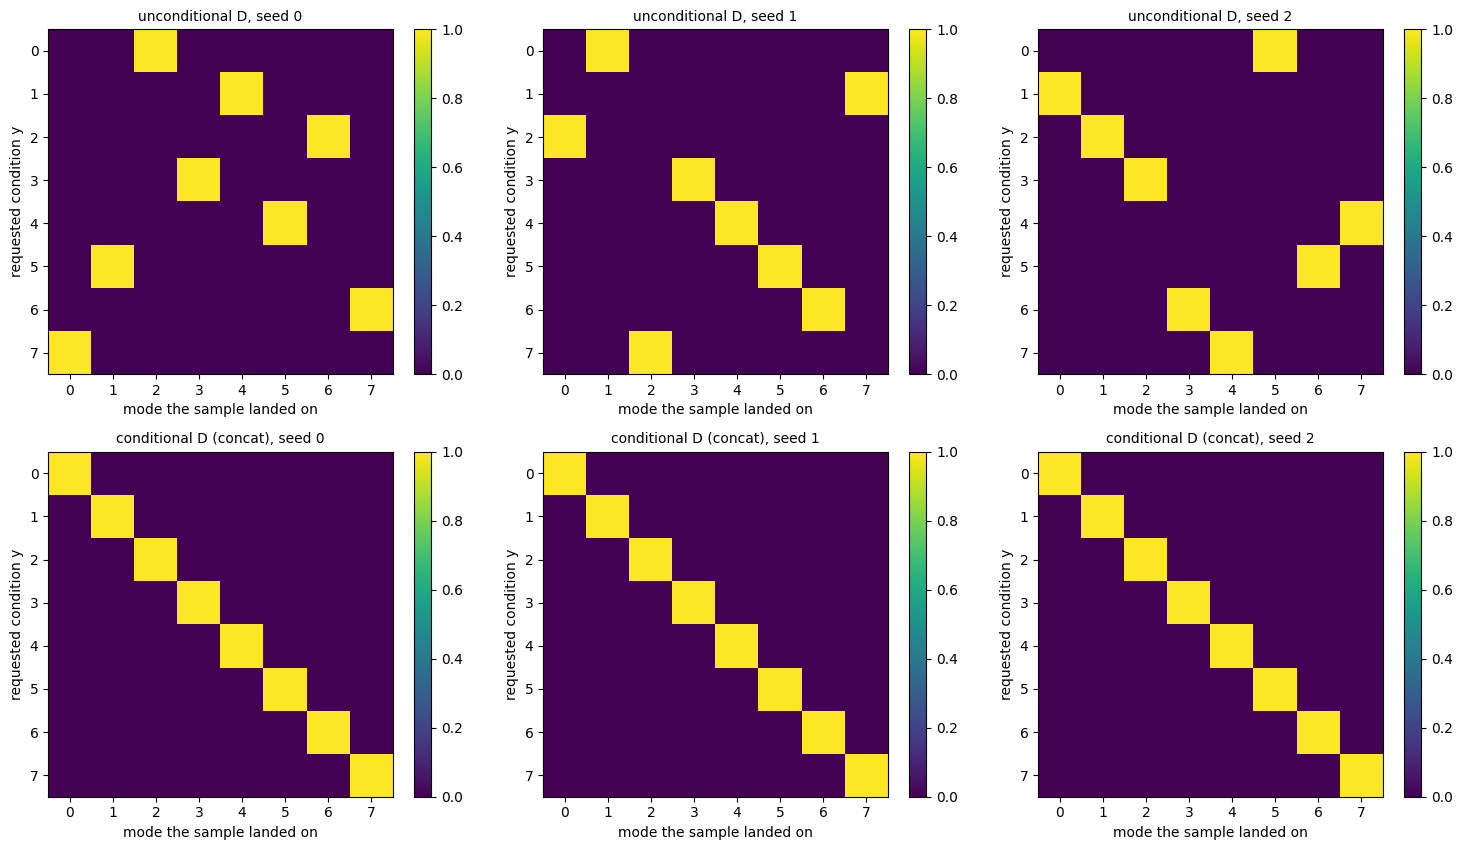

In [7]:
# ============================================================
# 図: 条件とモードの対応行列
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
for j, seed in enumerate([0, 1, 2]):
    for i, (tabs, name) in enumerate([(tables_nocond, "unconditional D"),
                                      (tables_concat, "conditional D (concat)")]):
        ax = axes[i, j]
        T = tabs[j] / tabs[j].sum(1, keepdims=True)
        im = ax.imshow(T, cmap="viridis", vmin=0, vmax=1)
        ax.set_xlabel("mode the sample landed on")
        ax.set_ylabel("requested condition y")
        ax.set_title(f"{name}, seed {seed}", fontsize=10)
        ax.set_xticks(range(K))
        ax.set_yticks(range(K))
        ax.grid(False)
        plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

### 読み取れること

#### 生成器は $y$ を無視していない — 完全に使っている

| 設定 | seed | 各条件の最頻モード | 置換か | 集中度 | 遵守率 |
|---|---|---|---|---|---|
| 無条件 D | 0 | [2, 4, 6, 3, 5, 1, 7, 0] | はい | **1.0000** | 0.1250 |
| 無条件 D | 1 | [1, 7, 0, 3, 4, 5, 6, 2] | はい | **1.0000** | 0.5000 |
| 無条件 D | 2 | [5, 0, 1, 2, 7, 6, 3, 4] | はい | **1.0000** | 0.0000 |
| concat | 0-2 | [0, 1, 2, 3, 4, 5, 6, 7] | はい（恒等） | 1.0000 | 1.0000 |

**集中度 1.0000** は、各条件のサンプルが1つのモードに**完全に**集まっていることを意味します。
$y$ は捨てられていません。むしろ完全に使われています。

決まっていないのは**対応**です。3シードすべてで、ラベルからモードへの写像は
**置換**になりました。遵守率 0.1250 / 0.5000 / 0.0000 は
「置換が偶然恒等と一致した要素数 ÷ 8」（1個 / 4個 / 0個）です。

#### なぜ置換になるか

無条件の判別器は**周辺分布しか見ません**。生成器が各 $y$ を1つのモードに割り当て、
全体で8モードを覆えば、周辺分布は完璧です。

$$\mathcal{L} \text{ は } \{y \to \text{mode}\} \text{ の選び方に依存しない}$$

**どの $y$ をどのモードに割るかは目的関数に現れません。** 勾配がゼロの方向です。
だから初期値で決まり、シードごとに変わります。

そして置換は全単射なので、**周辺分布の指標はすべて満点になります**
（占有率ちょうど $1/8$、ED 0.02536）。前節の4番目の観察はこれで説明できます。

#### 教訓 — 判別器が見ない情報は「無視される」のではなく「任意になる」

$D$ に $y$ を渡す理由は、生成器に $y$ を**使わせる**ためではありません。
生成器は勝手に使います。$y$ の**意味を固定する**ためです。

これは 182・194 で繰り返した「集計統計が構造を隠す」型の問題ですが、新しい点があります。
**自分で条件用の指標を定義しても足りませんでした。** 条件遵守率はまさに条件付けを
測るために作った指標ですが、置換のときシードごとに 0.0000 〜 0.5000 とばらつき、
seed 1 の 0.5000 は「半分うまくいっている」と誤読できます。
構造が見えたのは分割表を取ったからです。

<a id="methods"></a>
## 4. 条件付けの3方式

条件をモデルに入れる経路は1つではありません。代表的な3つを同じ条件で比べます。

### (a) concat — 埋め込みを連結する

$$D(x, y) = \psi\big([\,x;\, E y\,]\big)$$

最も単純。$y$ を埋め込んで入力に貼り付けるだけです。

### (b) projection discriminator

$$D(x, y) = \psi\big(f(x)\big) + \langle V y,\; f(x) \rangle$$

$f$ は $x$ の特徴抽出、$V y$ はラベルの埋め込み。**内積**で条件を入れます。
この形は「$\log p(x\mid y) - \log p(x)$ が $y$ について線形」という仮定から導かれ、
クラス数が多いときに concat より効くとされます。

### (c) AC-GAN — 補助分類器

判別器に $y$ を**入力しません**。代わりに $y$ を**予測する**ヘッドを足し、
損失に交差エントロピーを加えます。

$$\mathcal{L}_D = \mathcal{L}_{\text{adv}} + \lambda\big(
\mathrm{CE}(C(x_{\text{real}}), y_{\text{real}}) + \mathrm{CE}(C(x_{\text{fake}}), y_{\text{fake}})\big)$$

生成器も $\mathrm{CE}(C(G(z,y)), y)$ を下げようとします。

> **ここで予測を立てます。** (b) projection が最も良く、(a) concat が次、
> (c) AC-GAN は「分類しやすいサンプル」に寄る圧力があるので多様性を削るはず。
> この予測は**半分外れました**（結果は下）。

In [8]:
# ============================================================
# projection discriminator と AC-GAN
# ============================================================

class DiscProjection(nn.Module):
    # D(x, y) = psi(f(x)) + <V y, f(x)>
    def __init__(self, hidden=128):
        super().__init__()
        self.f = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2))
        self.psi = nn.Linear(hidden, 1)
        self.V = nn.Embedding(K, hidden)

    def forward(self, x, y=None):
        h = self.f(x)
        return self.psi(h).squeeze(-1) + (self.V(y) * h).sum(-1)


class DiscAC(nn.Module):
    # 真偽ヘッド + 補助分類器ヘッド。入力に y は入れない
    def __init__(self, hidden=128):
        super().__init__()
        self.f = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2))
        self.adv = nn.Linear(hidden, 1)
        self.cls = nn.Linear(hidden, K)

    def forward(self, x, y=None):
        return self.adv(self.f(x)).squeeze(-1)

    def logits(self, x):
        return self.cls(self.f(x))


def train_acgan(steps=4000, seed=0, batch=256, lr=2e-4, w_cls=1.0):
    torch.manual_seed(seed)
    G, D = GenCond(), DiscAC()
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    for _ in range(steps):
        i = torch.randint(0, len(X_train), (batch,))
        xr, yr = X_train[i], Y_train[i]
        yf = torch.randint(0, K, (batch,))
        xf = G(batch, yf).detach()
        ld = (bce(D(xr), torch.ones(batch)) + bce(D(xf), torch.zeros(batch))
              + w_cls * (F.cross_entropy(D.logits(xr), yr)
                         + F.cross_entropy(D.logits(xf), yf)))
        od.zero_grad()
        ld.backward()
        od.step()
        yg = torch.randint(0, K, (batch,))
        xg = G(batch, yg)
        og.zero_grad()
        (bce(D(xg), torch.ones(batch))
         + w_cls * F.cross_entropy(D.logits(xg), yg)).backward()
        og.step()
    return G

print("定義完了")

定義完了


In [9]:
# ============================================================
# 3方式の比較（3シード）
# ============================================================

METHODS = [
    ("(a) concat", lambda s: train_gan(GenCond, DiscConcat, True, True, seed=s)),
    ("(b) projection D", lambda s: train_gan(GenCond, DiscProjection, True, True, seed=s)),
    ("(c) AC-GAN", lambda s: train_acgan(seed=s)),
    ("(参考) 条件を D に渡さない", lambda s: train_gan(GenCond, DiscUncond, True, False, seed=s)),
]

t0 = time.time()
method_res = {}
print(f"{'方式':<26}{'遵守率':>9}{'周辺のED':>11}{'中心ずれ':>10}{'最悪中心ずれ':>13}"
      f"{'広がり':>9}{'条件別ED':>11}{'条件別ED最悪':>13}")
print("-" * 102)
for tag, fit in METHODS:
    ms = [eval_cond(fit(s)) for s in [0, 1, 2]]
    method_res[tag] = ms
    f = lambda k: np.array([m[k] for m in ms])
    print(f"{tag:<26}{f('adh').mean():9.4f}{f('ed').mean():11.5f}{f('cen').mean():10.4f}"
          f"{f('cenmax').mean():13.4f}{f('sp').mean():9.4f}"
          f"{f('ped').mean():11.5f}{f('pedmax').mean():13.5f}")
print("-" * 102)
print(f"3シードの平均。経過 {time.time() - t0:.0f}s")
print(f"基準（真のサンプル）: 広がり {sp_t:.4f}   条件別ED {ped_t:.5f}")
print()
print("シードごとの値（周辺の ED / 条件別 ED / 広がり）")
for tag, ms in method_res.items():
    f = lambda k: np.array([m[k] for m in ms])
    print(f"  {tag:<26} ED {np.round(f('ed'), 5)}  "
          f"条件別 {np.round(f('ped'), 4)}  広がり {np.round(f('sp'), 4)}")

方式                              遵守率      周辺のED      中心ずれ       最悪中心ずれ      広がり      条件別ED      条件別ED最悪
------------------------------------------------------------------------------------------------------


(a) concat                   1.0000    0.02532    0.2063       0.3486   0.1061    0.17761      0.33264


(b) projection D             1.0000    0.02839    0.2400       0.3969   0.1216    0.20391      0.41976


(c) AC-GAN                   1.0000    0.04189    0.2976       0.5952   0.1010    0.29235      0.74166


(参考) 条件を D に渡さない             0.2083    0.02040    3.2140       5.8126   0.1202    5.85797     11.01879
------------------------------------------------------------------------------------------------------
3シードの平均。経過 72s
基準（真のサンプル）: 広がり 0.2510   条件別ED 0.00079

シードごとの値（周辺の ED / 条件別 ED / 広がり）
  (a) concat                 ED [0.03347 0.02366 0.01882]  条件別 [0.2099 0.1701 0.1528]  広がり [0.0946 0.0731 0.1505]
  (b) projection D           ED [0.02888 0.01766 0.03863]  条件別 [0.1815 0.1184 0.3119]  広がり [0.1121 0.1276 0.125 ]
  (c) AC-GAN                 ED [0.03768 0.05015 0.03784]  条件別 [0.2703 0.3247 0.282 ]  広がり [0.1017 0.1007 0.1008]
  (参考) 条件を D に渡さない           ED [0.02042 0.02118 0.01959]  条件別 [6.6141 3.8908 7.069 ]  広がり [0.1354 0.1158 0.1094]


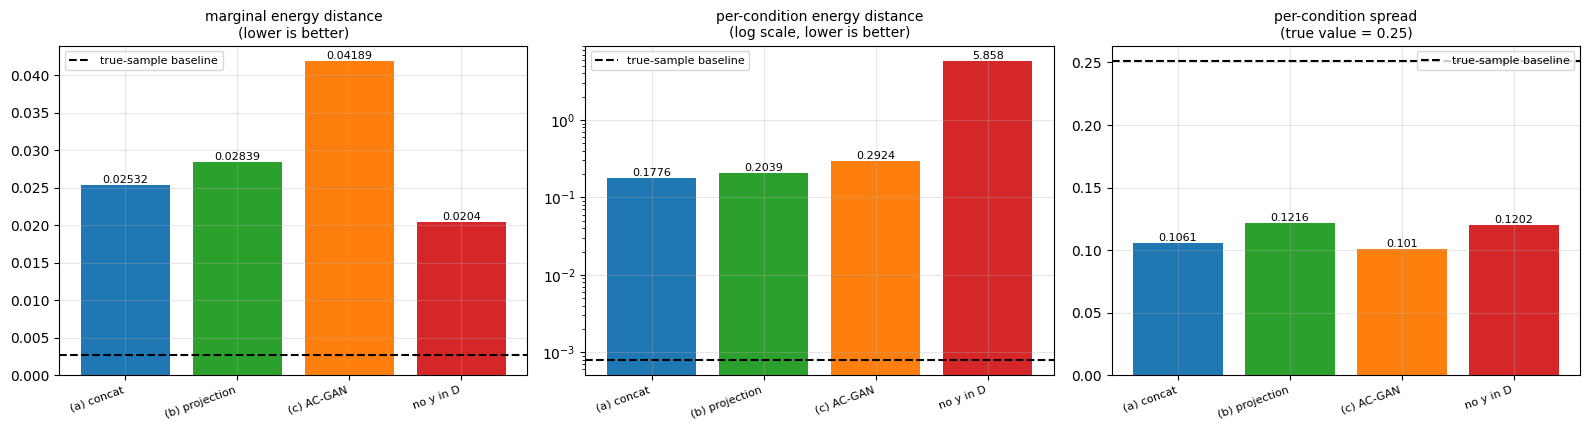

In [10]:
# ============================================================
# 図: 周辺の指標は順位を逆にする
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
names = list(method_res.keys())
names_en = ["(a) concat", "(b) projection", "(c) AC-GAN", "no y in D"]
colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"]

for ax, (key, title, ref) in zip(axes, [
        ("ed", "marginal energy distance\n(lower is better)", ped_t * 0 + energy_distance(Ts, X_ref)),
        ("ped", "per-condition energy distance\n(log scale, lower is better)", ped_t),
        ("sp", "per-condition spread\n(true value = 0.25)", sp_t)]):
    vals = [np.mean([m[key] for m in method_res[n]]) for n in names]
    ax.bar(range(len(names)), vals, color=colors)
    ax.axhline(ref, color="k", ls="--", lw=1.5, label="true-sample baseline")
    if key == "ped":
        ax.set_yscale("log")
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names_en, fontsize=8, rotation=20, ha="right")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.4g}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

### 読み取れること

#### 予測は半分外れた

| 方式 | 条件遵守率 | 周辺の ED | 条件別 ED | 広がり |
|---|---|---|---|---|
| (a) concat | 1.0000 | 0.02532 | **0.17761** | 0.1061 |
| (b) projection D | 1.0000 | 0.02839 | 0.20391 | 0.1216 |
| (c) AC-GAN | 1.0000 | 0.04189 | 0.29235 | **0.1010** |
| (参考) 条件を D に渡さない | 0.2083 | **0.02040** | 5.85797 | 0.1202 |
| 基準（真） | 1.0000 | 0.00274 | 0.00079 | 0.2510 |

**「projection が最良」という予測は外れました。** concat 0.17761 のほうが良い。
しかもシードごとに見ると

| 方式 | 条件別 ED（3シード） |
|---|---|
| (a) concat | 0.2099 / 0.1701 / 0.1528 |
| (b) projection | 0.1815 / 0.1184 / 0.3119 |

**範囲が重なっています。** この問題では両者の差はシード間のばらつきに埋もれます。
projection の利点はクラス数が多い・特徴次元が高い場合の話であり、
8クラス・2次元では測れません。

> 「効くとされる」工夫を、効く条件を測らずに採用してはいけません。
> 183 で「$\lambda$ の標準値 10」が壊れていたのと同じ構造です。

**「AC-GAN は多様性を削る」という予測は当たりました**（広がり 0.1010 が3方式で最小）。
しかも 3シードで 0.1017 / 0.1007 / 0.1008 と**異常に安定**しています。
補助分類器が「分類しやすい = モード中心に寄った」サンプルへ押す圧力は、
初期値に依らず同じ強さで働くわけです。条件別 ED 0.29235 も concat の範囲と重なりません。

#### 周辺の指標は順位を逆にする

周辺の ED で最良なのは **「条件を D に渡さない」0.02040** — 完全に壊れたモデルです。
条件別 ED で見ると 5.85797、concat の **33 倍**悪い。

> **条件付きモデルを周辺分布の指標で評価してはいけません。**
> FID も ED も、条件を無視したモデルを満点と評価します。

#### 遵守率 1.0 は必要条件にすぎない

concat の条件別 ED は基準 0.00079 に対して 0.17761 — **225 倍**です。
遵守率 1.0000（指定したモードに必ず落ちる）でも、**各条件の分布としては合っていません**。
広がりが真の 2.4 分の1 だからです。
「正しいモードに落ちた」と「正しい分布を出した」は別の主張です。

<a id="knobs"></a>
## 5. 忠実度と多様性のつまみ — 切断トリックと CFG

条件付き生成では「条件にどれだけ従わせるか」を推論時に調整したくなります。
2系統それぞれに標準的な道具があります。

| 系統 | 道具 | やること |
|---|---|---|
| GAN | **切断トリック**（truncation） | $z$ を打ち切った正規分布から引く |
| 拡散 | **CFG**（42章） | $\tilde\epsilon = \epsilon_u + w(\epsilon_c - \epsilon_u)$ |

どちらも「忠実度と多様性を交換するつまみ」と説明されます。
**同じ8峰リング・同じ指標で両方測ると、交換の中身が違いました。**

### まず式を見比べる

切断は $z$ の**範囲**を変えます。生成は $x = G(z, y)$ のままです。

CFG は**予測そのもの**を変えます。$w=1$ で $\tilde\epsilon = \epsilon_c$、
$w>1$ は $\epsilon_c$ を**通り過ぎます**。

$$\tilde\epsilon = \epsilon_u + w(\epsilon_c - \epsilon_u)
= \epsilon_c + (w-1)(\epsilon_c - \epsilon_u)$$

右の形にすると分かりやすい: **$w>1$ は内挿ではなく外挿です。**
この違いが測定に出ます。

In [11]:
# ============================================================
# 切断トリック（GAN）
# ============================================================

def trunc_randn(n, d, thr, gen=None):
    out = torch.randn(n, d, generator=gen)
    for _ in range(200):
        bad = out.abs() > thr
        if not bad.any():
            break
        out[bad] = torch.randn(int(bad.sum()), generator=gen)
    return out


@torch.no_grad()
def sample_trunc(G, y, thr=None):
    z = torch.randn(len(y), G.z_dim) if thr is None else trunc_randn(len(y), G.z_dim, thr)
    return G.net(torch.cat([z, G.emb(y)], -1))


G_trunc = train_gan(GenCond, DiscConcat, True, True, seed=0)
y_eval = torch.arange(K).repeat_interleave(1250)

print("切断トリック — z の打ち切り閾値を振る")
print(f"{'閾値':>7}{'遵守率':>9}{'中心ずれ':>10}{'広がり':>9}{'最近傍距離':>12}{'ED':>10}")
print("-" * 57)
trunc_rows = []
for thr in [None, 3.0, 2.0, 1.5, 1.0, 0.5, 0.25]:
    S = sample_trunc(G_trunc, y_eval, thr)
    Sp, yp = shuffled(S, y_eval)
    cen, _, sp, _, _ = per_condition(S, y_eval)
    row = (thr, adherence(Sp, yp), cen, sp, nn_distance(Sp), energy_distance(Sp, X_ref))
    trunc_rows.append(row)
    lab = "なし" if thr is None else f"{thr:.2f}"
    print(f"{lab:>7}{row[1]:9.4f}{row[2]:10.4f}{row[3]:9.4f}{row[4]:12.5f}{row[5]:10.5f}")
print("-" * 57)
print(f"基準（真）: 広がり {sp_t:.4f}  最近傍距離 {nn_distance(Ts):.5f}  "
      f"ED {energy_distance(Ts, X_ref):.5f}")

切断トリック — z の打ち切り閾値を振る
     閾値      遵守率      中心ずれ      広がり       最近傍距離        ED
---------------------------------------------------------
     なし   1.0000    0.2334   0.0946     0.00578   0.03129
   3.00   1.0000    0.2327   0.0933     0.00578   0.02589
   2.00   1.0000    0.2309   0.0827     0.00507   0.03065
   1.50   1.0000    0.2338   0.0708     0.00414   0.03821
   1.00   1.0000    0.2320   0.0513     0.00309   0.03491
   0.50   1.0000    0.2321   0.0270     0.00138   0.03780
   0.25   1.0000    0.2322   0.0137     0.00098   0.04496
---------------------------------------------------------
基準（真）: 広がり 0.2510  最近傍距離 0.02315  ED 0.00274


In [12]:
# ============================================================
# 条件付き拡散モデルと CFG（42章を同じ指標で測り直す）
# ============================================================

T_DIFF = 200
betas = torch.linspace(1e-4, 0.02, T_DIFF)
alphas = 1 - betas
abar = torch.cumprod(alphas, 0)


class EpsNet(nn.Module):
    def __init__(self, hidden=128, t_emb=16, y_emb=16):
        super().__init__()
        self.temb = nn.Embedding(T_DIFF, t_emb)
        self.yemb = nn.Embedding(K + 1, y_emb)       # 最後の 1 つが無条件トークン
        self.net = nn.Sequential(
            nn.Linear(2 + t_emb + y_emb, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, x, t, y):
        return self.net(torch.cat([x, self.temb(t), self.yemb(y)], -1))


def train_diffusion(steps=12000, batch=256, lr=2e-3, seed=0, p_uncond=0.1):
    torch.manual_seed(seed)
    m = EpsNet()
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        i = torch.randint(0, len(X_train), (batch,))
        x0, y = X_train[i], Y_train[i].clone()
        y[torch.rand(batch) < p_uncond] = K          # ラベルドロップ
        t = torch.randint(0, T_DIFF, (batch,))
        e = torch.randn(batch, 2)
        xt = abar[t].sqrt()[:, None] * x0 + (1 - abar[t]).sqrt()[:, None] * e
        opt.zero_grad()
        ((m(xt, t, y) - e) ** 2).mean().backward()
        opt.step()
        sch.step()
    return m


@torch.no_grad()
def sample_cfg(m, y, w, seed=0):
    g = torch.Generator().manual_seed(seed)
    n = len(y)
    x = torch.randn(n, 2, generator=g)
    y_null = torch.full_like(y, K)
    for ti in range(T_DIFF - 1, -1, -1):
        t = torch.full((n,), ti, dtype=torch.long)
        e_c, e_u = m(x, t, y), m(x, t, y_null)
        e = e_u + w * (e_c - e_u)
        mean = (x - betas[ti] / (1 - abar[ti]).sqrt() * e) / alphas[ti].sqrt()
        x = mean if ti == 0 else mean + betas[ti].sqrt() * torch.randn(n, 2, generator=g)
    return x


t0 = time.time()
DIFF = train_diffusion()
print(f"拡散モデルの学習 {time.time() - t0:.0f}s")

y_cfg = torch.arange(K).repeat_interleave(500)
print()
print("CFG のガイダンススケール w を振る")
print(f"{'w':>6}{'遵守率':>9}{'中心ずれ':>10}{'広がり':>9}{'最近傍距離':>12}{'ED':>10}")
print("-" * 56)
cfg_rows = []
for w in [0.0, 1.0, 1.5, 2.0, 3.0, 5.0, 7.0, 10.0]:
    S = sample_cfg(DIFF, y_cfg, w)
    Sp, yp = shuffled(S, y_cfg)
    cen, _, sp, _, _ = per_condition(S, y_cfg)
    row = (w, adherence(Sp, yp), cen, sp, nn_distance(Sp, 2000),
           energy_distance(Sp, X_ref, 2000))
    cfg_rows.append(row)
    print(f"{w:6.1f}{row[1]:9.4f}{row[2]:10.4f}{row[3]:9.4f}{row[4]:12.5f}{row[5]:10.5f}")
print("-" * 56)
TR4, YT4 = sample_ring(4000, seed=7)
TR4s, YT4s = shuffled(TR4, YT4)
cen4, _, sp4, _, _ = per_condition(TR4, YT4)
print(f"基準（真 4000点）: 遵守率 {adherence(TR4s, YT4s):.4f}  中心ずれ {cen4:.4f}  "
      f"広がり {sp4:.4f}  最近傍 {nn_distance(TR4s, 2000):.5f}  "
      f"ED {energy_distance(TR4s, X_ref, 2000):.5f}")

拡散モデルの学習 9s

CFG のガイダンススケール w を振る
     w      遵守率      中心ずれ      広がり       最近傍距離        ED
--------------------------------------------------------


   0.0   0.1287    2.9481   2.1221     0.02946   0.00430


   1.0   1.0000    0.0222   0.2542     0.02852   0.00385


   1.5   1.0000    0.0171   0.2498     0.02766   0.00340


   2.0   1.0000    0.0327   0.2546     0.02835   0.00528


   3.0   1.0000    0.0620   0.2711     0.03149   0.00377


   5.0   1.0000    0.1384   0.3304     0.03495   0.01460


   7.0   1.0000    0.4577   0.6952     0.03948   0.04756


  10.0   1.0000    2.6623   2.2826     0.04249   0.49947
--------------------------------------------------------
基準（真 4000点）: 遵守率 1.0000  中心ずれ 0.0176  広がり 0.2479  最近傍 0.02839  ED 0.00272


### $w>1$ が効くのはどんなときか — 仮説を立てて測る

上の表で予想外のことが起きていたら、原因を切り分けます。

$w>1$ は $\epsilon_c$ の**外挿**です。外挿が改善になるのは、
$\epsilon_c$ 自体が**条件を十分に表現できていない**ときだけのはずです。
$\epsilon_c$ が既に正しければ、通り過ぎることは害でしかありません。

> **仮説**: $w=1$ での誤差が大きいモデルほど、最適な $w$ は 1 より大きくなる。

拡散モデルの学習を途中で打ち切って $\epsilon_c$ の当てはまりを段階的に悪くし、
各モデルで最適な $w$ を探します。

指標は**中心ずれ**を使います。ED はこの問題では値が小さすぎて
真のサンプル同士の誤差（雑音床）に埋もれるためです（第7節のつまずき 3）。

In [13]:
# ============================================================
# 仮説の検証: 条件の当てはまりが悪いほど最適な w は大きいか
# ============================================================

y_w = torch.arange(K).repeat_interleave(500)

def cen_sp(m, w):
    S = sample_cfg(m, y_w, w)
    cen, _, sp, _, _ = per_condition(S, y_w)
    return cen, sp


WS = [1.0, 1.5, 2.0, 3.0, 5.0]
t0 = time.time()
hdr = "".join(("w=%g" % w).rjust(9) for w in WS)
print(f"{'モデル':<22}" + hdr + f"{'最適w':>7}{'w=1の広がり':>13}{'最適wの広がり':>15}")
print("-" * (22 + 9 * len(WS) + 7 + 28))
cfgw_rows = []
for tag, kw in [("標準（12000歩）", dict()),
                ("6000歩で打ち切り", dict(steps=6000)),
                ("1500歩で打ち切り", dict(steps=1500)),
                ("600歩で打ち切り", dict(steps=600)),
                ("250歩で打ち切り", dict(steps=250))]:
    m = train_diffusion(**kw)
    res = [cen_sp(m, w) for w in WS]
    cens = [r[0] for r in res]
    sps = [r[1] for r in res]
    bi = int(np.argmin(cens))
    cfgw_rows.append((tag, cens, sps, WS[bi]))
    print(f"{tag:<22}" + "".join(f"{c:9.4f}" for c in cens)
          + f"{WS[bi]:7.1f}{sps[0]:13.4f}{sps[bi]:15.4f}")
print("-" * (22 + 9 * len(WS) + 7 + 28))
print(f"表の数値は条件ごとの中心ずれ（小さいほど条件に忠実）。経過 {time.time() - t0:.0f}s")
print(f"基準（真 4000点）: 中心ずれ {cen4:.4f}  広がり {sp4:.4f}")
print()
print("外挿で中心ずれが何倍改善したか")
for tag, cens, sps, bw in cfgw_rows:
    print(f"  {tag:<22} w=1 で {cens[0]:.4f} -> 最適 w={bw} で {min(cens):.4f}  "
          f"({cens[0] / min(cens):.2f}倍の改善)")

モデル                         w=1    w=1.5      w=2      w=3      w=5    最適w      w=1の広がり        最適wの広がり
------------------------------------------------------------------------------------------------------


標準（12000歩）               0.0222   0.0171   0.0327   0.0620   0.1384    1.5       0.2542         0.2498


6000歩で打ち切り               0.0274   0.0248   0.0536   0.1069   0.2537    1.5       0.2530         0.2272


1500歩で打ち切り               0.0344   0.0226   0.0322   0.0422   0.0581    1.5       0.2284         0.1586


600歩で打ち切り                0.1665   0.0295   0.0741   0.1181   0.1464    1.5       0.3061         0.2003


250歩で打ち切り                0.3858   0.1627   0.0972   0.0878   0.0923    3.0       0.4574         0.1632
------------------------------------------------------------------------------------------------------
表の数値は条件ごとの中心ずれ（小さいほど条件に忠実）。経過 25s
基準（真 4000点）: 中心ずれ 0.0176  広がり 0.2479

外挿で中心ずれが何倍改善したか
  標準（12000歩）             w=1 で 0.0222 -> 最適 w=1.5 で 0.0171  (1.30倍の改善)
  6000歩で打ち切り             w=1 で 0.0274 -> 最適 w=1.5 で 0.0248  (1.11倍の改善)
  1500歩で打ち切り             w=1 で 0.0344 -> 最適 w=1.5 で 0.0226  (1.53倍の改善)
  600歩で打ち切り              w=1 で 0.1665 -> 最適 w=1.5 で 0.0295  (5.64倍の改善)
  250歩で打ち切り              w=1 で 0.3858 -> 最適 w=3.0 で 0.0878  (4.39倍の改善)


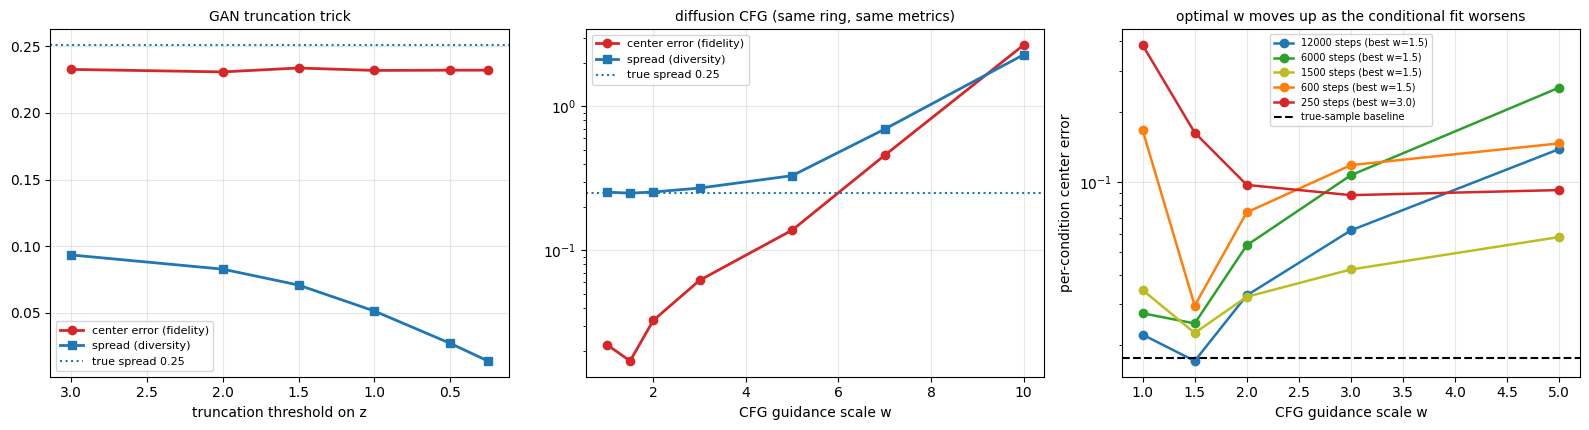

In [14]:
# ============================================================
# 図: 切断トリックと CFG を同じ軸で比べる
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

thrs = [r[0] for r in trunc_rows][1:]
ax = axes[0]
ax.plot(thrs, [r[2] for r in trunc_rows][1:], "o-", lw=2, color="tab:red",
        label="center error (fidelity)")
ax.plot(thrs, [r[3] for r in trunc_rows][1:], "s-", lw=2, color="tab:blue",
        label="spread (diversity)")
ax.axhline(sp_t, color="tab:blue", ls=":", lw=1.5, label="true spread 0.25")
ax.set_xlabel("truncation threshold on z")
ax.set_title("GAN truncation trick", fontsize=10)
ax.invert_xaxis()
ax.legend(fontsize=8)

ws = [r[0] for r in cfg_rows][1:]
ax = axes[1]
ax.plot(ws, [r[2] for r in cfg_rows][1:], "o-", lw=2, color="tab:red",
        label="center error (fidelity)")
ax.plot(ws, [r[3] for r in cfg_rows][1:], "s-", lw=2, color="tab:blue",
        label="spread (diversity)")
ax.axhline(sp_t, color="tab:blue", ls=":", lw=1.5, label="true spread 0.25")
ax.set_xlabel("CFG guidance scale w")
ax.set_yscale("log")
ax.set_title("diffusion CFG (same ring, same metrics)", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]
steps_en = ["12000 steps", "6000 steps", "1500 steps", "600 steps", "250 steps"]
for (tag, cens, sps, bw), c, nm in zip(cfgw_rows,
                                       ["tab:blue", "tab:green", "tab:olive",
                                        "tab:orange", "tab:red"], steps_en):
    ax.plot(WS, cens, "o-", lw=1.8, color=c, label=f"{nm} (best w={bw})")
ax.axhline(cen4, color="k", ls="--", lw=1.5, label="true-sample baseline")
ax.set_xlabel("CFG guidance scale w")
ax.set_ylabel("per-condition center error")
ax.set_yscale("log")
ax.set_title("optimal w moves up as the conditional fit worsens", fontsize=10)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 読み取れること

#### 切断トリックは忠実度に効かない

| 閾値 | 中心ずれ（忠実度） | 広がり（多様性） | ED |
|---|---|---|---|
| なし | 0.2334 | 0.0946 | 0.03129 |
| 2.00 | 0.2309 | 0.0827 | 0.03065 |
| 1.00 | 0.2320 | 0.0513 | 0.03491 |
| 0.25 | **0.2322** | **0.0137** | **0.04496** |
| 基準（真） | 0.0069 | 0.2510 | 0.00274 |

広がりは 0.0946 → 0.0137（**6.9 分の1**）まで落ちるのに、
中心ずれは 0.2334 → 0.2322 で**動きません**（変化 0.5%）。

理由は式を見れば分かります。切断は $z$ の**範囲**だけを変え、写像 $G(\cdot, y)$ は変えません。
$z$ を原点対称に打ち切るので、条件 $y$ の生成サンプルの平均はほとんど動きません。
**減るのは多様性だけです。**

そして ED は 0.03129 → 0.04496 と**悪化**します。このモデルは既に広がりが
真の 2.7 分の1 なので、削る余地が無いのです。

> **切断トリックは「モデルが広がりすぎている」ときの道具です。**
> 既に狭いモデルに使うと、多様性だけが減って分布は悪くなります。

#### CFG — 42章の「$w$ = 3〜5 がバランス」はこの設定では成り立たない

| $w$ | 条件遵守率 | 中心ずれ | 広がり |
|---|---|---|---|
| 0.0（無条件） | 0.1287 | 2.9481 | 2.1221 |
| 1.0 | 1.0000 | 0.0222 | 0.2542 |
| **1.5** | 1.0000 | **0.0171** | **0.2498** |
| 2.0 | 1.0000 | 0.0327 | 0.2546 |
| 3.0 | 1.0000 | 0.0620（3.6倍悪化） | 0.2711 |
| 5.0 | 1.0000 | 0.1384（8.1倍悪化） | 0.3304 |
| 7.0 | 1.0000 | 0.4577 | 0.6952 |
| 10.0 | 1.0000 | 2.6623 | 2.2826 |
| 基準（真） | 1.0000 | 0.0176 | 0.2479 |

最小は $w = 1.5$ の 0.0171 で、**真のサンプル同士の誤差 0.0176 と同等**です。
つまり測定の雑音床に達しています。

$w$ = 3〜5 では中心ずれが 3.6 倍 / 8.1 倍**悪化**します。
そして広がりは $w$ とともに**増えます**（0.2498 → 0.2711 → 0.3304 → 0.6952 → 2.2826）。
減りません。

> この設定で CFG は忠実度と多様性を**交換していません**。
> $w > 1.5$ は両方を悪化させます。42章の「$w$ = 3〜5 がバランス」は
> ここには当てはまりません。

#### 仮説は支持された — $w > 1$ は外挿なので、当てはまりが悪いときだけ効く

| モデル | $w=1$ の中心ずれ | 最適 $w$ | 改善 | $w=1$ の広がり |
|---|---|---|---|---|
| 標準（12000歩） | 0.0222 | 1.5 | 1.30 倍 | 0.2542 |
| 6000歩 | 0.0274 | 1.5 | 1.11 倍 | 0.2530 |
| 1500歩 | 0.0344 | 1.5 | 1.53 倍 | 0.2284 |
| 600歩 | 0.1665 | 1.5 | 5.64 倍 | 0.3061 |
| **250歩** | **0.3858** | **3.0** | 4.39 倍 | **0.4574** |

$w=1$ での誤差が 0.0222 のモデルは最適 $w$ が 1.5、誤差 0.3858 のモデルは **3.0** になりました。
外挿による改善も、当てはまりの悪化とともに 1.30 倍 → 5.64 倍へ増えます。

**ただし言えることは限定的です。** 最適 $w$ が動いたのは 1.5 → 3.0 の1段だけで、
600歩（誤差 0.1665）はまだ 1.5 です。測った範囲で主張できるのは
「条件の当てはまりが十分に悪くなると最適 $w$ は 1.5 を超える」までで、
「$w$ が誤差の単調関数である」とは示せていません。

#### 2つのつまみに共通する構造

250歩 の行の広がりを見てください。$w=1$ で **0.4574** — 真の 0.2479 の 1.8 倍に
**膨らんでいます**。ここでは $w$ を上げると広がりが 0.1632 に落ち、
忠実度が 4.39 倍改善します。**確かに多様性を削って忠実度を買っています。**

切断トリックの結論と同じ形です。

> **どちらのつまみも、「モデルが広がりすぎている」ときにだけ交換が成立します。**
> 広がりが足りないモデルに使うと、削るだけで何も買えません。
> つまみを回す前に、モデルの広がりを真の値と比べて測ることです。

実務で $w$ = 3〜7 が効くのは、高次元の画像で $\epsilon_c$ が条件を十分に表現できていない
（上の表の 250歩 に相当する）状況だからです。
2次元の8峰では $\epsilon_c$ がほぼ正しいので、外挿の余地が 1.5 までしかありません。

<a id="continuous"></a>
## 6. 条件が連続値のとき

ここまでラベルは離散（8クラス）でした。実務では条件が連続値のことがあります
（角度・強度・時刻・年齢）。扱い方は3通りあります。

| 方式 | 条件の表現 |
|---|---|
| 離散ビン | 値を8分割して one-hot にする |
| 連続・生の値 | 値をそのまま 1 次元で渡す |
| 連続・特徴量 | 値を $(\cos\theta, \sin\theta)$ に変換して渡す |

データを変えます。リング上の点を**連続な角度 $\theta$** で条件付けます。

$$x \mid \theta \sim \mathcal{N}\big((3\cos\theta,\, 3\sin\theta),\; 0.15^2 I\big)$$

さらに **$\theta$ の一部の帯を学習データから除外**します。
学習に無い条件を指定したとき、モデルが外挿できるかを測るためです。

In [15]:
# ============================================================
# 連続な条件付け — 除外帯つきのデータ
# ============================================================

R_C, SD_C = 3.0, 0.15
HOLD_C, HOLD_W = math.pi / 2, 0.35        # 学習から外す角度の帯
N_BIN = 8

def sample_theta(n, seed=0, exclude=True):
    g = torch.Generator().manual_seed(seed)
    out = []
    while sum(len(o) for o in out) < n:
        t = torch.rand(4 * n, generator=g) * 2 * math.pi
        if exclude:
            t = t[(t - HOLD_C).abs() > HOLD_W]
        out.append(t)
    t = torch.cat(out)[:n]
    x = torch.stack([R_C * t.cos(), R_C * t.sin()], -1) + SD_C * torch.randn(n, 2, generator=g)
    return x, t


Xc, Tc = sample_theta(12000, seed=0)
print(f"学習データ {len(Xc)}点。角度 {HOLD_C:.3f} ± {HOLD_W} の帯を除外"
      f"（全周の {HOLD_W / math.pi * 100:.1f}%）")
print(f"除外帯に入る学習点: {int(((Tc - HOLD_C).abs() < HOLD_W).sum())} 点")

def to_bin(t):
    return (t / (2 * math.pi) * N_BIN).long().clamp(0, N_BIN - 1)

enc_onehot = lambda t: torch.eye(N_BIN)[to_bin(t)]
enc_raw = lambda t: (t / (2 * math.pi))[:, None]          # 0 と 2pi がつながらない
enc_cossin = lambda t: torch.stack([t.cos(), t.sin()], -1)


class GenC(nn.Module):
    def __init__(self, c_dim, hidden=128, z_dim=2):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim + c_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2))

    def forward(self, c):
        return self.net(torch.cat([torch.randn(len(c), self.z_dim), c], -1))


class DiscC(nn.Module):
    def __init__(self, c_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 + c_dim, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))

    def forward(self, x, c):
        return self.net(torch.cat([x, c], -1)).squeeze(-1)


def train_cont(enc, c_dim, steps=5000, seed=0, batch=256, lr=2e-4):
    torch.manual_seed(seed)
    G, D = GenC(c_dim), DiscC(c_dim)
    og = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    od = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    for _ in range(steps):
        i = torch.randint(0, len(Xc), (batch,))
        xr, cr = Xc[i], enc(Tc[i])
        j = torch.randint(0, len(Xc), (batch,))
        cf = enc(Tc[j])
        xf = G(cf).detach()
        od.zero_grad()
        (bce(D(xr, cr), torch.ones(batch))
         + bce(D(xf, cf), torch.zeros(batch))).backward()
        od.step()
        j2 = torch.randint(0, len(Xc), (batch,))
        c2 = enc(Tc[j2])
        og.zero_grad()
        bce(D(G(c2), c2), torch.ones(batch)).backward()
        og.step()
    return G


t0 = time.time()
CONT = {"離散8ビン": (train_cont(enc_onehot, N_BIN), enc_onehot),
        "連続・生のθ": (train_cont(enc_raw, 1), enc_raw),
        "連続・(cos,sin)": (train_cont(enc_cossin, 2), enc_cossin)}
print(f"3モデルの学習 {time.time() - t0:.0f}s")

学習データ 12000点。角度 1.571 ± 0.35 の帯を除外（全周の 11.1%）
除外帯に入る学習点: 0 点


3モデルの学習 19s


In [16]:
# ============================================================
# 指定角度での中心ずれ
# ============================================================

bin_center = lambda t: (to_bin(torch.tensor([t])).item() + 0.5) * 2 * math.pi / N_BIN
TEST_T = [0.0, 0.2, 0.39, 0.6, 0.79, 1.0, 1.18, 1.40, HOLD_C, 1.75,
          1.96, 2.36, 3.14, 3.93, 4.71, 5.50, 6.1]

print("指定角度 θ での「生成サンプルの平均が真の中心からどれだけ離れているか」")
print(f"{'θ':>7}{'域':>12}{'ビン中心との差':>15}{'離散8ビン':>11}{'生のθ':>9}{'(cos,sin)':>11}")
print("-" * 65)
cont_err = {k: [] for k in CONT}
for tt in TEST_T:
    th = torch.full((2000,), tt)
    target = torch.tensor([R_C * math.cos(tt), R_C * math.sin(tt)])
    e = {}
    for name, (m, enc) in CONT.items():
        with torch.no_grad():
            S = m(enc(th))
        e[name] = float((S.mean(0) - target).norm())
        cont_err[name].append(e[name])
    region = "外（除外帯）" if abs(tt - HOLD_C) < HOLD_W else "内"
    print(f"{tt:7.2f}{region:>12}{abs(tt - bin_center(tt)):15.3f}"
          f"{e['離散8ビン']:11.4f}{e['連続・生のθ']:9.4f}{e['連続・(cos,sin)']:11.4f}")
print("-" * 65)
inside = [i for i, tt in enumerate(TEST_T) if abs(tt - HOLD_C) >= HOLD_W]
outside = [i for i, tt in enumerate(TEST_T) if abs(tt - HOLD_C) < HOLD_W]
print()
for name in CONT:
    a = np.array(cont_err[name])
    print(f"  {name:<18} 学習域 {a[inside].mean():.4f}   除外帯 {a[outside].mean():.4f}   "
          f"(除外帯/学習域 {a[outside].mean() / a[inside].mean():.2f}倍)")
print()
a = np.array(cont_err["離散8ビン"])
d = np.array([abs(tt - bin_center(tt)) for tt in TEST_T])
CORR_BIN = float(np.corrcoef(a, d)[0, 1])
CONT_EN = ["discrete 8 bins", "continuous, raw theta", "continuous, (cos,sin)"]
print(f"離散ビン: 中心ずれと「ビン中心からの距離」の相関 {CORR_BIN:+.4f}")
print(f"  ビン中心に近い点（距離<0.1）の平均 {a[d < 0.1].mean():.4f} / "
      f"遠い点（距離>0.3）{a[d > 0.3].mean():.4f}")

指定角度 θ での「生成サンプルの平均が真の中心からどれだけ離れているか」
      θ           域        ビン中心との差      離散8ビン      生のθ  (cos,sin)
-----------------------------------------------------------------
   0.00           内          0.393     1.1027   0.3751     0.1920
   0.20           内          0.193     0.5083   0.1156     0.1802
   0.39           内          0.003     0.1300   0.0477     0.1651
   0.60           内          0.207     0.7250   0.0955     0.1413
   0.79           内          0.388     0.4865   0.0661     0.1140
   1.00           内          0.178     0.1458   0.0311     0.0792
   1.18           内          0.002     0.6750   0.1212     0.0467
   1.40      外（除外帯）          0.222     1.3229   0.2417     0.0114
   1.57      外（除外帯）          0.393     1.3885   0.3303     0.0231
   1.75      外（除外帯）          0.213     0.8692   0.3973     0.0513
   1.96           内          0.003     0.3089   0.4394     0.0814
   2.36           内          0.389     0.9561   0.4963     0.1249
   3.14           内          0.391    

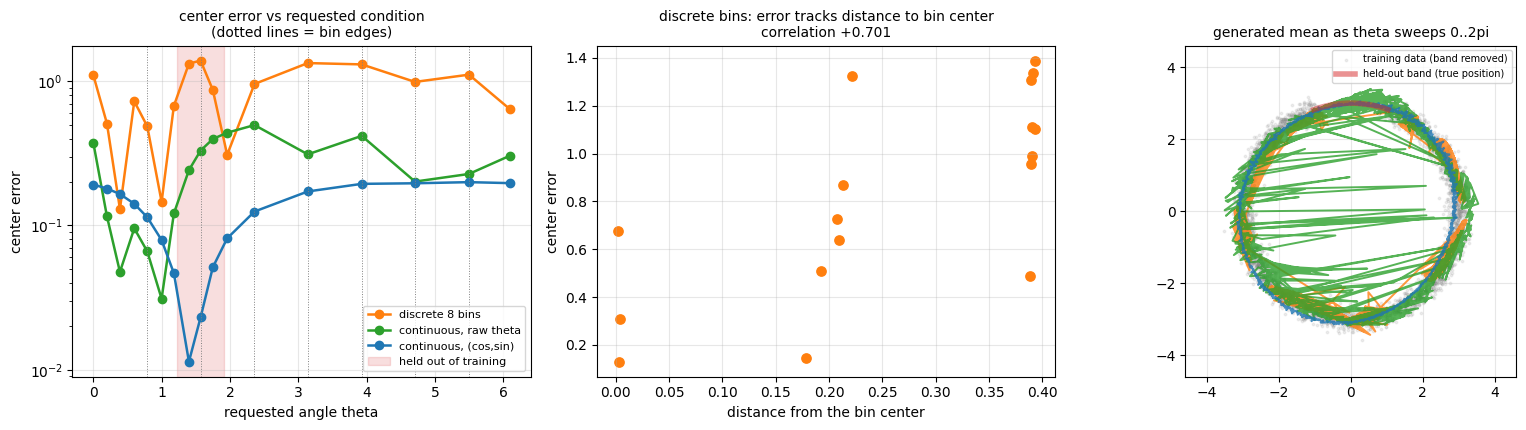

In [17]:
# ============================================================
# 図: 連続な条件への追従と外挿
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

ax = axes[0]
for name, c, label_en in zip(CONT, ["tab:orange", "tab:green", "tab:blue"], CONT_EN):
    ax.plot(TEST_T, cont_err[name], "o-", lw=1.8, color=c, label=label_en)
ax.axvspan(HOLD_C - HOLD_W, HOLD_C + HOLD_W, color="tab:red", alpha=0.15,
           label="held out of training")
for b in range(1, N_BIN):
    ax.axvline(b * 2 * math.pi / N_BIN, color="gray", ls=":", lw=0.7)
ax.set_xlabel("requested angle theta")
ax.set_ylabel("center error")
ax.set_yscale("log")
ax.set_title("center error vs requested condition\n(dotted lines = bin edges)", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
name_bin = list(CONT)[0]
ax.scatter(d, cont_err[name_bin], s=45, color="tab:orange")
ax.set_xlabel("distance from the bin center")
ax.set_ylabel("center error")
ax.set_title(f"discrete bins: error tracks distance to bin center\n"
             f"correlation {CORR_BIN:+.3f}", fontsize=10)

ax = axes[2]
th = torch.linspace(0, 2 * math.pi, 1200)
ax.scatter(Xc[:4000, 0], Xc[:4000, 1], s=3, alpha=0.12, color="tab:gray",
           label="training data (band removed)")
for name, c in zip(CONT, ["tab:orange", "tab:green", "tab:blue"]):
    m, enc = CONT[name]
    with torch.no_grad():
        S = m(enc(th))
    ax.plot(S[:, 0], S[:, 1], lw=1.4, color=c, alpha=0.8)
hb = torch.linspace(HOLD_C - HOLD_W, HOLD_C + HOLD_W, 60)
ax.plot(R_C * hb.cos(), R_C * hb.sin(), lw=4, color="tab:red", alpha=0.5,
        label="held-out band (true position)")
ax.set_aspect("equal")
ax.set_xlim(-4.6, 4.6)
ax.set_ylim(-4.6, 4.6)
ax.set_title("generated mean as theta sweeps 0..2pi", fontsize=10)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### 読み取れること

#### 離散ビンの解像度は「指定の解像度」ではなく「ビン幅」で決まる

| 方式 | 学習域の中心ずれ | 除外帯 | 除外帯/学習域 |
|---|---|---|---|
| 離散8ビン（one-hot） | 0.7440 | 1.1935 | 1.60 倍 |
| 連続・生の $\theta$ | 0.2322 | 0.3231 | 1.39 倍 |
| 連続・$(\cos\theta, \sin\theta)$ | 0.1488 | **0.0286** | **0.19 倍** |

離散ビンの誤差は、**ビン中心からの距離と相関 +0.7013** で動きます。

| | 平均の中心ずれ |
|---|---|
| ビン中心に近い点（距離 < 0.1） | 0.3713 |
| 遠い点（距離 > 0.3） | 1.0840（**2.9 倍**） |

ビン幅 $2\pi/8 = 0.785$ rad は弧長 2.36 に相当します。
ビン内のどこを指定しても同じ one-hot になるので、
**ビン内平均に落ちる誤差がそのまま出ます**。$\theta = 0.39$（ビン 0 の中心）での
誤差 0.1300 と、$\theta = 0.00$（ビン端）での 1.1027 を比べてください。

#### 「連続値にすれば外挿できる」は条件の表現に依存する

同じ連続値でも結果が違いました。

- **生の $\theta$**: 除外帯で 1.39 倍悪化（0.2322 → 0.3231）
- **$(\cos\theta, \sin\theta)$**: 悪化しない（0.1488 → 0.0286）

差の理由は、条件から目標への写像の形です。目標の中心は

$$\mu(\theta) = (3\cos\theta,\; 3\sin\theta) = 3\,c \quad\text{where}\quad c = (\cos\theta, \sin\theta)$$

$(\cos\theta,\sin\theta)$ で渡すと、この写像は**線形**です。
だから学習に無い帯も線形補間で埋まります。
生の $\theta$ では正弦関数を学ぶ必要があり、しかも $\theta = 0$ と $2\pi$ が
表現上**切れている**（0.0 で 0.3751、6.1 で 0.3045 と両端で誤差が大きい）。

> 条件を連続値にすること自体に効果はありません。
> **条件の特徴量が目標の滑らかな（できれば線形な）関数になっているか**が効きます。

#### 除外帯が学習域より良いのをどう読むか

$(\cos\theta,\sin\theta)$ の除外帯 0.0286 は学習域の平均 0.1488 より**小さい**。
奇妙ですが、学習域の誤差は条件付けの誤差ではなく **GAN の学習雑音**が支配しているためです
（$\theta$ = 0, 3.93, 5.50 などで一様に 0.19 前後）。
除外帯は帯の中央に当たり、両側から最も補間しやすい位置にあります。

つまり「外挿できた」と言えるのは**この帯の幅（全周の 11.1%）とこの写像の形での話**で、
外挿が一般に易しいという主張ではありません。

<a id="pitfalls"></a>
## 7. 実装でつまずいた3点

本章は**指標の側で**3回つまずきました。モデルの実装ではありません。
条件付きモデルの評価は、無条件モデルの評価より壊れやすいということです。

### (1) ラベル順に並んだサンプルを先頭から切り取った

条件付きモデルを評価するには、条件ごとに同数のサンプルを作ります。
自然に書くとこうなります。

```python
y = torch.arange(K).repeat_interleave(1250)   # [0,0,...,1,1,...,7,7,...]
S = G(len(y), y)
energy_distance(S, X_ref)                      # ← 内部で S[:3000] を取る
```

ED も最近傍距離も、計算量のために**先頭 $n$ 個しか見ません**。
先頭 3000 個は条件 0・1・2 だけです。8条件のうち 2.4 条件を
全8モードの参照分布と比べることになります。

次のセルで実際に測ります。

In [18]:
# ============================================================
# つまずき (1) を再現する
# ============================================================

y_ord = torch.arange(K).repeat_interleave(1250)
with torch.no_grad():
    S_ord = G_trunc(len(y_ord), y_ord)
S_shuf, _ = shuffled(S_ord, y_ord)

ed_ord = energy_distance(S_ord, X_ref)
ed_shuf = energy_distance(S_shuf, X_ref)
print(f"ラベル順のまま  ED {ed_ord:.5f}   先頭3000点に含まれる条件の数 "
      f"{len(set(y_ord[:3000].tolist()))}")
print(f"並べ替えてから  ED {ed_shuf:.5f}   先頭3000点に含まれる条件の数 "
      f"{len(set(shuffled(S_ord, y_ord)[1][:3000].tolist()))}")
print(f"-> 並べ替えないと ED を {ed_ord / ed_shuf:.0f} 倍に過大評価する")
print()
print(f"最近傍距離: ラベル順 {nn_distance(S_ord):.5f} / 並べ替え {nn_distance(S_shuf):.5f}")
print("-> こちらは逆に小さく出る（狭い領域に密集した点だけを見るため）")

ラベル順のまま  ED 2.23497   先頭3000点に含まれる条件の数 3
並べ替えてから  ED 0.03071   先頭3000点に含まれる条件の数 8
-> 並べ替えないと ED を 73 倍に過大評価する

最近傍距離: ラベル順 0.00276 / 並べ替え 0.00569
-> こちらは逆に小さく出る（狭い領域に密集した点だけを見るため）


**教訓**: サブサンプリングする指標に渡す配列は、**順序に意味が無いことを確認する**。
無条件モデルでは生成順がそのまま無作為なので、この罠は踏みません。
条件付きモデルに切り替えた瞬間に現れます。

### (2) 占有率の最大偏差が恒等的に 0 になった

182 で主役だった指標が、条件付きモデルでは厳密に 0.0000 を返しました。
バグではなく、$y$ を一様に選んでいるからです（第2節）。

**教訓**: 指標が「完璧」を返したとき、まずその指標がその設定で
**何を測れるのか**を確認する。測定結果ではなく定義であることがあります。

### (3) ED が雑音床に埋もれて CFG の $w$ を比較できなかった

CFG の $w$ を比べる最初の試みでは ED を使いました。ところが

- 真のサンプル同士の ED が 0.00272
- $w$ = 1, 1.5, 2, 3 の ED が 0.00385 / 0.00340 / 0.00528 / 0.00377

**比べたい差が基準の誤差と同じ桁**です。実際、評価サンプルの並べ替えの乱数を
変えるだけで $w$ の順位が入れ替わりました。

条件ごとの中心ずれ（500点の平均位置）に替えると、
0.0222 / 0.0171 / 0.0327 / 0.0620 と明確に分かれました。
平均位置は $n$ 点の平均なので、分布全体の距離より分散がずっと小さいためです。

**教訓**: 比べたい差が基準の誤差より小さければ、その指標では比べられません。
指標を替えるか、サンプル数を増やすか、どちらかです。
183 で「仮説を棄却するときも測り方を疑う」と書きましたが、
**順位を読むときも測り方を疑う**のが同じ規律です。

<a id="summary"></a>
## 8. まとめとチートシート

### 測った数値

| 問い | 答え | 根拠 |
|---|---|---|
| 条件付けは 182 の比率の誤りを直すか | **直すのではなく消す**。最大偏差 0.0913 → 厳密に 0.0000 | $y$ を一様に選ぶので定義から従う |
| 183 の宿題（$W_1$ は 8峰で比率を直すか） | **直す**。0.0913 → 0.0170（5.4 分の1）、シード間比 4.5倍 → 1.3倍 | $y$ を選んでいないので本物 |
| 条件付けの代償は | **(c) 多様性の欠如**。広がり 0.1117（真の 2.2 分の1）、最近傍 0.00705（3.3 分の1） | |
| $D$ に $y$ を渡さないと | 生成器は $y$ を**完全に使う**（集中度 1.0000）が、対応が**任意の置換**になる | 3シードすべて置換 |
| 周辺分布の指標で条件付きモデルを評価できるか | **できない**。壊れたモデルが周辺 ED 0.02040 で最良、条件別 ED では 33 倍悪い | |
| concat / projection / AC-GAN の順位 | concat ≈ projection（**差はばらつきに埋もれる**）> AC-GAN（一貫して悪い・最も潰れる） | 条件別 ED の3シード範囲が重なる |
| 切断トリックは忠実度を上げるか | **上げない**。広がり 6.9 分の1 に対し中心ずれは 0.5% しか動かない | |
| CFG の $w$ = 3〜5 は良いか | この設定では**悪い**。中心ずれ 3.6 倍 / 8.1 倍悪化、広がりも**増える** | 最適は 1.5 |
| $w > 1$ が効く条件は | $\epsilon_c$ の当てはまりが悪いとき。$w=1$ の誤差 0.0222 → 最適 1.5、0.3858 → 最適 **3.0** | |
| 連続値で条件付ければ外挿できるか | **条件の表現次第**。生の $\theta$ は除外帯で 1.39 倍悪化、$(\cos,\sin)$ は悪化しない | 写像が線形になるかどうか |

### 指標の選び方（条件付きモデル）

| 測りたいこと | 使う指標 | 使えない指標 |
|---|---|---|
| どのモードがどれだけ出たか | — | 占有率（**恒等的に 0**） |
| 条件が効いているか | 条件ごとの中心ずれ、分割表 | 周辺の ED・FID（壊れたモデルを満点にする） |
| 条件の意味が合っているか | 分割表（置換を見分ける） | 条件遵守率単独（置換でシードごとに 0.0〜0.5） |
| 各条件の分布が合っているか | 条件別 ED、広がり | 条件遵守率（必要条件にすぎない） |
| つまみを回す前の判断 | 広がりを真の値と比べる | — |

### 他の章との接続

| 章 | 本章との関係 |
|---|---|
| **182** | 占有率という主要指標が条件付きモデルでは使えなくなる。(b) が消えて (c) が出る |
| **183** | 宿題（8峰での比率の誤り）を閉じた。「標準値を疑う」が projection と $w$ で再現した |
| **42** | CFG の「$w$ = 3〜5」を数値で検証し、成り立つ条件（$\epsilon_c$ の当てはまりが悪いこと）を特定した |
| **194** | 集計統計が構造を隠す型。本章は「自分で定義した指標でも足りない」まで進んだ |
| **196** | 6系統の比較に「条件付けの扱いやすさ」という軸を足せる |
| **185 ProGAN / StyleGAN** | 条件を**どこに**入れるか（AdaIN でスタイルとして入れる）。本章の3方式の延長 |
| **186 VQ-GAN** | 条件が離散トークン列になる。本章の「離散ビンの解像度」が効く |

### 次章へ

185 では条件を**層ごとに**入れます（StyleGAN の AdaIN）。
本章で測った「条件の意味が固定されない」問題は、スタイル混合の
解釈可能性にそのまま繋がります。

<a id="quiz"></a>
## 9. 自己評価クイズ

1. 条件付き GAN の占有率の最大偏差が厳密に 0.0000 になった。
   これはモデルが比率を正しく学んだ証拠か。理由を述べよ。

2. 「条件付き G / 無条件 D」の設定で、条件遵守率が 0.1250（偶然と同じ）だった。
   生成器は $y$ を無視しているか。集中度 1.0000 という観測をどう説明するか。

3. ある条件付きモデル A の周辺 ED が 0.020、別のモデル B の周辺 ED が 0.029 だった。
   A のほうが良いと結論してよいか。追加で何を測るべきか。

4. concat と projection discriminator の条件別 ED が
   0.17761 と 0.20391 だった。concat が優れていると結論してよいか。

5. 切断トリックで $z$ を強く打ち切ったのに、条件ごとの中心ずれが変わらなかった。
   式のどの性質からそう言えるか。

6. CFG を $\tilde\epsilon = \epsilon_c + (w-1)(\epsilon_c - \epsilon_u)$ と書き直すと、
   $w > 1$ が改善になる条件は何か。$w = 10$ で中心ずれが 2.6623 まで悪化した理由を述べよ。

7. 角度 $\theta$ で条件付けるとき、one-hot の 8 ビンでは
   $\theta = 0.39$ の誤差が 0.1300、$\theta = 0.00$ の誤差が 1.1027 だった。
   この差はどこから来るか。

8. 同じ連続値でも、生の $\theta$ は除外帯で 1.39 倍悪化し、
   $(\cos\theta, \sin\theta)$ は悪化しなかった。この差を生む条件を一般的に述べよ。

9. CFG の $w$ を比べるのに ED が使えなかった。どういう状況で指標が「使えない」と
   判断すべきか、本章の数値を使って説明せよ。

10. 条件付きモデルを1つの数値で評価する指標を1つだけ選べと言われたら何を選ぶか。
    その指標が見落とすものは何か。

---

### 解答の指針

1. **証拠にならない。** 生成時に $y$ を一様に選んでいるので、遵守率が 1 なら
   占有率は定義から $1/8$ になる。比率を決めているのはモデルではなくサンプリング側。
   182 の主要指標が条件付きモデルでは恒等式になる。

2. **無視していない。** 集中度 1.0000 は各条件が1モードに完全に集まることを意味し、
   $y$ は完全に使われている。決まっていないのは対応で、3シードすべて置換になった。
   無条件 $D$ は周辺分布しか見ないので、$y \to$ モードの選び方が目的関数に現れない。

3. **結論できない。** 本章では完全に壊れたモデルが周辺 ED 0.02040 で最良だった。
   条件ごとの中心ずれと条件別 ED を測る。分割表で置換かどうかを見る。

4. **できない。** 3シードの範囲が 0.1528〜0.2099 と 0.1184〜0.3119 で重なる。
   差はシード間のばらつきに埋もれている。182 の「ばらつきは絶対値で比べる」と同じ。

5. 切断は $z$ の**範囲**だけを変え、写像 $G(\cdot, y)$ を変えない。
   原点対称な打ち切りなので条件ごとの平均はほとんど動かない。
   変わるのは広がりだけ（6.9 分の1）。

6. $\epsilon_c$ が条件を十分に表現できていないときだけ改善になる。
   $w>1$ は $\epsilon_c$ を**通り過ぎる外挿**なので、$\epsilon_c$ が既に正しければ害にしかならない。
   $w=10$ では外挿が大きすぎてサンプルがリングの外へ飛ぶ（広がり 2.2826）。

7. $\theta = 0.39$ はビン 0 の中心、$\theta = 0.00$ はビン端。
   ビン内のどこを指定しても同じ one-hot になるので、
   誤差はビン内平均からのずれ、つまり**ビン中心からの距離**で決まる（相関 +0.7013）。

8. 条件の特徴量から目標への写像が滑らか（できれば線形）かどうか。
   $\mu(\theta) = 3(\cos\theta, \sin\theta)$ なので $(\cos,\sin)$ では線形になり補間で埋まる。
   生の $\theta$ では正弦関数を学ぶ必要があり、$0$ と $2\pi$ の接続も切れている。

9. 比べたい差が**基準の誤差と同じ桁**になったとき。本章では真のサンプル同士の ED が
   0.00272 で、$w$ = 1〜3 の ED が 0.00340〜0.00528 だった。
   実際に並べ替えの乱数だけで順位が入れ替わった。中心ずれ（0.0171〜0.0620）に替えて解決した。

10. 1つ選ぶなら**条件別 ED**（条件ごとに分布距離を測り平均する）。
    置換も多様性の欠如も捉える。見落とすのは条件**間**の関係
    （例: 隣接する条件が滑らかに変化するか）と、条件ごとの標本数が少ないときの推定誤差。
    本章で $(\cos,\sin)$ の外挿を見るのに中心ずれを使ったのは、まさにこの穴を埋めるため。